In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import GWFish.modules as gw


os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # use GPU 1

name="75_150"

waveform_model = 'IMRPhenomXPHM'
f_ref = 20.
detectors = ['ET']
network = gw.detection.Network(detector_ids = detectors, detection_SNR = (0., 8.))


/home/tpausch/.conda/envs/ET-DINGO/lib/python3.10/site-packages/lalsimulation/_lalsimulation_swig.py:8: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## Load Model

In [2]:
from dingo.core.posterior_models.build_model import build_model_from_kwargs
main_pm = build_model_from_kwargs(
    filename=f"/scratch/tpausch/models/{name}/model_latest.pt",
    device="cuda",
    load_training_info=False,
)

model= main_pm


WARNING!

This object was created using Dingo version 0.1.dev1230+gc9da5d765 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



Putting posterior model to device cuda.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt(f"/scratch/tpausch/models/{name}/history.txt")
epochs   = data[:, 0]
train    = data[:, 1]
val      = data[:, 2]


plt.figure(figsize=(8, 5))
plt.plot(epochs, train, label="Train loss")
plt.plot(epochs, val,   label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Log-likelihood")
plt.legend()
plt.title("Dingo training history")
plt.tight_layout()
plt.show()

## Simulate Injections


In [7]:
import dingo.gw.injection as injection
from dingo.gw.noise.asd_dataset import ASDDataset

# ============================================================
# Setup
# ============================================================

num_injections = 1_000
out_dir = f"/scratch/tpausch/test_data/{name}/injections"
os.makedirs(out_dir, exist_ok=True)

np.random.seed(42)  # optional, for reproducibility

injection_generator = injection.Injection.from_posterior_model_metadata(
    main_pm.metadata
)

asd_fname = "/home/tpausch/ET-Dingo/MUSICA/asds_ET_T8.hdf5"
asd_dataset = ASDDataset(file_name=asd_fname)

injection_generator.asd = {
    k: v[0] for k, v in asd_dataset.asds.items()
}

# This is the combined intrinsic + extrinsic bilby PriorDict
# that the network was trained on
prior = injection_generator.prior
print(prior)

# ============================================================
# Draw and run injections
# ============================================================

for idx in range(num_injections):

    print(f"Running injection {idx}")

    theta = prior.sample()
    theta = {k: float(v) for k, v in theta.items()}  # cast numpy -> float

    strain_data = injection_generator.injection(theta)

    payload = {
        "theta_true": theta,
        "strain_data": strain_data,
    }

    fname = os.path.join(out_dir, f"inj_{idx:04d}.pkl")

    with open(fname, "wb") as f:
        pickle.dump(payload, f)

Setting spin_conversion_phase = 0.0. Using this value for the phase parameter for conversion to cartesian spins.
Loading dataset from /home/tpausch/ET-Dingo/MUSICA/asds_ET_T8.hdf5.
{'mass_1': Constraint(minimum=86, maximum=535, name='mass_1', latex_label='$m_1$', unit=None), 'mass_2': Constraint(minimum=33, maximum=173, name='mass_2', latex_label='$m_2$', unit=None), 'chirp_mass': bilby.gw.prior.UniformInComponentsChirpMass(minimum=75, maximum=150, name='chirp_mass', latex_label='$\\mathcal{M}$', unit=None, boundary=None), 'mass_ratio': bilby.gw.prior.UniformInComponentsMassRatio(minimum=0.125, maximum=1.0, name='mass_ratio', latex_label='$q$', unit=None, boundary=None, equal_mass=False), 'phase': Uniform(minimum=0.0, maximum=6.283185307179586, name='phase', latex_label='$\\phi$', unit=None, boundary='periodic'), 'chi_1': bilby.gw.prior.AlignedSpin(a_prior=Uniform(minimum=0, maximum=0.9, name=None, latex_label=None, unit=None, boundary=None), z_prior=Uniform(minimum=-1, maximum=1, name

## Infere parameters

In [4]:
from bilby.gw.detector import InterferometerList
print([ifo.name for ifo in InterferometerList(["ET-1", "ET-2", "ET-3"])])

['ET-1', 'ET-2', 'ET-3']


In [5]:
#%%capture  
#avoids printing a lot of output to the notebook
import pandas as pd
from dingo.gw.inference.sampler import GWComposedSampler




os.makedirs(f"/scratch/tpausch/test_data/{name}/results", exist_ok=True)

injection_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/injections"))

#first 100 injections
for fname in injection_files[:1000]:

    # --------------------------------------------------------
    # Load injection
    # --------------------------------------------------------

    with open(f"/scratch/tpausch/test_data/{name}/injections/{fname}", "rb") as f:
        payload = pickle.load(f)

    theta_true = payload["theta_true"]
    strain_data = payload["strain_data"]

    # --------------------------------------------------------
    # Run sampler
    # --------------------------------------------------------

    sampler = GWComposedSampler.from_model(model, strain_data)


    sampler.run_sampler(
        num_samples=5_000,
        batch_size=5_000,
    )

    result = sampler.to_result()



    # --------------------------------------------------------
    # calculate network SNR
    # --------------------------------------------------------
    parameters = pd.DataFrame(
        {key: np.array([np.asarray(val).item()]) for key, val in theta_true.items()}
    )
    snr_df = gw.utilities.get_snr(parameters, network, waveform_model, f_ref)
    network_snr = float(snr_df["network"].iloc[0])  # extract as plain float

    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    result_payload = {
        "theta_true": theta_true,
        "result": result,
        "network_snr": network_snr,
    }

    outname = fname.replace("inj_", "result_")

    with open(f"/scratch/tpausch/test_data/{name}/results/{outname}", "wb") as f:
        pickle.dump(result_payload, f)

    print(f"Saved /scratch/tpausch/test_data/{name}/results/{outname}")


WARNING!

This object was created using Dingo version 0.1.dev1174+g45666b754 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



Saved /scratch/tpausch/test_data/75_150/results/result_0000.pkl


WARNING!

This object was created using Dingo version 0.1.dev1174+g45666b754 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



Saved /scratch/tpausch/test_data/75_150/results/result_0001.pkl


WARNING!

This object was created using Dingo version 0.1.dev1174+g45666b754 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



...

Saved /scratch/tpausch/test_data/75_150/results/result_0997.pkl


WARNING!

This object was created using Dingo version 0.1.dev1174+g45666b754 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



Saved /scratch/tpausch/test_data/75_150/results/result_0998.pkl


WARNING!

This object was created using Dingo version 0.1.dev1174+g45666b754 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.ligo.org/pe/pe-group-coordination/-/issues/1#note_1469386.



Saved /scratch/tpausch/test_data/75_150/results/result_0999.pkl


# Compare mean and median


In [6]:
def plot_chirpmass_mean_vs_median(name, cm_min, cm_max, bin_width=50,
                                  percentile=95, bin_on="true"):
    """
    Compare |mean - true| and |median - true| of the chirp-mass posterior,
    per chirp-mass bin.

    percentile : which percentile of |error| to show per bin (50 = typical error)
    bin_on     : "true" -> bin on true chirp mass (same bins for both estimators)
                 "mean" / "median" -> bin on that estimator's inferred value
    """
    true_cm, cm_mean_list, cm_median_list = [], [], []

    results_dir = f"/scratch/tpausch/test_data/{name}/results"
    for fname in sorted(os.listdir(results_dir)):
        with open(f"{results_dir}/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]
        t_cm = theta_true["chirp_mass"]
        if not (cm_min <= t_cm <= cm_max):
            continue

        cm_samples = np.array(payload["result"].samples["chirp_mass"])

        true_cm.append(t_cm)
        cm_mean_list.append(np.mean(cm_samples))
        cm_median_list.append(np.median(cm_samples))

    true_cm = np.array(true_cm)
    cm_mean = np.array(cm_mean_list)
    cm_median = np.array(cm_median_list)

    err_mean = np.abs(cm_mean - true_cm)
    err_median = np.abs(cm_median - true_cm)

    # ------------------------------------------------------------
    # Binning
    # ------------------------------------------------------------
    edges = np.append(np.arange(cm_min, cm_max, bin_width), cm_max)
    n_bins = len(edges) - 1

    x_for_bins = {"true": true_cm, "mean": cm_mean, "median": cm_median}[bin_on]
    bin_idx = np.clip(np.digitize(x_for_bins, edges) - 1, 0, n_bins - 1)

    stat_mean = np.full(n_bins, np.nan)
    stat_median = np.full(n_bins, np.nan)
    counts = np.zeros(n_bins, dtype=int)

    for i in range(n_bins):
        mask = bin_idx == i
        counts[i] = mask.sum()
        if counts[i] > 0:
            stat_mean[i] = np.percentile(err_mean[mask], percentile)
            stat_median[i] = np.percentile(err_median[mask], percentile)

    filled = counts > 0
    left = edges[:-1][filled]
    s_mean = stat_mean[filled]
    s_median = stat_median[filled]
    n_filled = counts[filled]

    # ------------------------------------------------------------
    # Plot: grouped bars, mean vs. median
    # ------------------------------------------------------------
    plt.figure(figsize=(16, 10))
    w = bin_width / 2
    plt.bar(left, s_mean, width=w, align="edge",
            color="tab:blue", edgecolor="black", alpha=0.8, label="mean")
    plt.bar(left + w, s_median, width=w, align="edge",
            color="tab:orange", edgecolor="black", alpha=0.8, label="median")

    for l, h1, h2, n in zip(left, s_mean, s_median, n_filled):
        plt.text(l + w, max(h1, h2), f"n={n}", ha="center", va="bottom", fontsize=8)

    xlabel = {"true": "True", "mean": "Inferred (mean)", "median": "Inferred (median)"}[bin_on]
    plt.xlabel(f"{xlabel} chirp mass")
    plt.ylabel(f"p{percentile} of |estimate − true| chirp mass")
    plt.title(f"Chirp-mass error: mean vs. median "
              f"(p{percentile} per {bin_width}-wide bin)")
    plt.grid(True, axis="y")
    for y in range(25, 176, 25):
        plt.axhline(y, linestyle="-", color="black", linewidth=0.8)
    plt.legend(title="point estimate", loc="upper left")
    plt.tight_layout()
    plt.show()

    # Quick numeric summary over all events
    print(f"Overall p{percentile}:  mean = {np.percentile(err_mean, percentile):.2f},  "
          f"median = {np.percentile(err_median, percentile):.2f}")
    print(f"Overall median |err|:  mean = {np.median(err_mean):.2f},  "
          f"median = {np.median(err_median):.2f}")

    return 0

In [7]:
plot_chirpmass_mean_vs_median(name, 50, 1000, bin_width=50, percentile=90, bin_on="true")

KeyboardInterrupt: 

# Plot Chirpmass error on median


In [8]:
def scatter_chirpmass(name, min, max):
    CM_MIN, CM_MAX = min, max
    true_cm = []
    true_mr = []
    mass_ratio_error = []
    mass_ratio_std = []
    chirp_mass_error = []
    chirp_mass_std = []


    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

          # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        if not (CM_MIN <= true_chirp_mass <= CM_MAX):
            continue

        result = payload["result"]

        posterior_samples = result.samples


        cm_samples = np.array(posterior_samples["chirp_mass"])

        cm_median = np.median(cm_samples)
        cm_std = np.std(cm_samples)

        true_mr.append(theta_true["mass_ratio"])
        true_cm.append(theta_true["chirp_mass"])
        #mass_ratio_error.append(q_mean - true_q)
        #mass_ratio_std.append(q_std)
        chirp_mass_error.append(cm_median - theta_true["chirp_mass"])
        chirp_mass_std.append(cm_std)


    true_mr = np.array(true_mr)
    true_cm = np.array(true_cm)

    # ------------------------------------------------------------
    # Error bars
    # ------------------------------------------------------------

    #plt.errorbar(
    #    true_cm,
    #    chirp_mass_error,
    #    yerr=chirp_mass_std,
    #    fmt="none",
    #    capsize=4,
    #    alpha=0.5,
    #    color="gray",
    #)

    # ------------------------------------------------------------
    # Colored scatter points
    # ------------------------------------------------------------

    sc = plt.scatter(
        true_cm,
        chirp_mass_error,
        s=20,
        edgecolor="black",
        alpha=0.3
    )

    # ------------------------------------------------------------
    # Reference line
    # ------------------------------------------------------------

    plt.axhline(0, linestyle="--", color="black")


    # ------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------

    plt.xlabel("True chirp mass")
    plt.ylabel("Chirp mass inference error (inferred − true)")

    plt.title("Chirp-mass inference error")

    plt.grid(True)

    plt.tight_layout()
    plt.show()

    cm_err = np.asarray(chirp_mass_error)

    mean_error = np.mean(cm_err)          # signed average bias (over/under-estimation)
    mean_abs_error = np.mean(np.abs(cm_err))  # average magnitude of deviation
    rms_error = np.sqrt(np.mean(cm_err**2))   # RMS deviation, penalizes outliers more
    std_error = np.std(cm_err)            # spread of the errors around their mean
    p90_abs_error = np.percentile(np.abs(cm_err), 90)
    p95_abs_error = np.percentile(np.abs(cm_err), 95)
    p98_abs_error = np.percentile(np.abs(cm_err), 98)
    p99_abs_error = np.percentile(np.abs(cm_err), 99)


    print(len(cm_err), "samples in range", CM_MIN, "-", CM_MAX)
    print(f"Mean error (bias):      {mean_error:.3f}")
    print(f"Mean absolute error:    {mean_abs_error:.3f}")
    print(f"RMS error:              {rms_error:.3f}")
    print(f"Std of error:           {std_error:.3f}")
    print(f"90th percentile |error|: {p90_abs_error:.3f}")
    print(f"95th percentile |error|: {p95_abs_error:.3f}")
    print(f"98th percentile |error|: {p98_abs_error:.3f}")
    print(f"99th percentile |error|: {p99_abs_error:.3f}")
    return 0

In [9]:
def hist_chirpmass_909598(name, min, max, bin_width=50):
    CM_MIN, CM_MAX = min, max
    true_cm = []
    true_mr = []
    mass_ratio_error = []
    mass_ratio_std = []
    chirp_mass_error = []
    chirp_mass_std = []
    inferred_cm = [] 

    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

        # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        if not (CM_MIN <= true_chirp_mass <= CM_MAX):
            continue

        result = payload["result"]
        posterior_samples = result.samples

        cm_samples = np.array(posterior_samples["chirp_mass"])
        cm_median = np.median(cm_samples)
        cm_std = np.std(cm_samples)
        inferred_cm.append(cm_median)

        true_mr.append(theta_true["mass_ratio"])
        true_cm.append(theta_true["chirp_mass"])
        chirp_mass_error.append(cm_median - theta_true["chirp_mass"])
        chirp_mass_std.append(cm_std)

    true_mr = np.array(true_mr)
    true_cm = np.array(true_cm)
    cm_err = np.asarray(chirp_mass_error)
    inferred_cm = np.array(inferred_cm)

    # ------------------------------------------------------------
    # Histogram: p95 of |error| per chirp-mass bin
    # ------------------------------------------------------------
    edges = np.arange(CM_MIN, CM_MAX + bin_width, bin_width)
    bin_idx = np.digitize(inferred_cm, edges) - 1
    edges = np.arange(CM_MIN, CM_MAX, bin_width)
    edges = np.append(edges, CM_MAX)

    p90_per_bin = np.full(len(edges) - 1, np.nan)
    p95_per_bin = np.full(len(edges) - 1, np.nan)
    p98_per_bin = np.full(len(edges) - 1, np.nan)
    counts = np.zeros(len(edges) - 1, dtype=int)

    for i in range(len(edges) - 1):
        in_bin = np.abs(cm_err[bin_idx == i])
        counts[i] = len(in_bin)
        if len(in_bin) > 0:
            p90_per_bin[i], p95_per_bin[i], p98_per_bin[i] = np.percentile(in_bin, [90, 95, 98])

    filled = counts > 0
    left = edges[:-1][filled]
    p90 = p90_per_bin[filled]
    p95 = p95_per_bin[filled]
    p98 = p98_per_bin[filled]


    plt.figure(figsize=(16, 10))
    # blue: 0 -> p90, purple: p90 -> p95, red: p95 -> p98
    plt.bar(left, p90, width=bin_width, align="edge",
            color="tab:blue", edgecolor="black", alpha=0.8, label="p90")
    plt.bar(left, p95 - p90, bottom=p90, width=bin_width, align="edge",
            color="purple", edgecolor="black", alpha=0.8, label="p95")
    plt.bar(left, p98 - p95, bottom=p95, width=bin_width, align="edge",
            color="red", edgecolor="black", alpha=0.8, label="p98")

    # annotate number of events per bin (above the top of the stack)
    for l, h, n in zip(left, p98, counts[filled]):
        plt.text(l + bin_width / 2, h, f"n={n}", ha="center", va="bottom", fontsize=8)
    plt.xlabel("Infered chirp mass")
    plt.ylabel("95th percentile of |inferred − true| chirp mass")
    plt.title(f"Chirp-mass inference error (p95 per {bin_width}-wide bin of inferred mass)")
    plt.grid(True, axis="y")
    plt.tight_layout()
    plt.axhline(25, linestyle="-", color="black")
    plt.axhline(50, linestyle="-", color="black")
    plt.axhline(75, linestyle="-", color="black")
    plt.axhline(100, linestyle="-", color="black")
    plt.axhline(125, linestyle="-", color="black")
    plt.axhline(150, linestyle="-", color="black")
    plt.axhline(175, linestyle="-", color="black")
    plt.legend(title="|error| percentile", loc="upper left")
    plt.show()


    return 0

In [10]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt


def binned_percentile(x, err, edges, perr):
    """p<perr> of |err| and event count for each bin defined by edges."""
    idx = np.digitize(x, edges) - 1
    abs_err = np.abs(err)
    vals = np.full(len(edges) - 1, np.nan)
    counts = np.zeros(len(edges) - 1, dtype=int)
    for i in range(len(edges) - 1):
        in_bin = abs_err[idx == i]
        counts[i] = len(in_bin)
        if len(in_bin) > 0:
            vals[i] = np.percentile(in_bin, perr)
    return vals, counts


def edges_from_pilot(x, err, pilot_edges, lo, hi, perr, step=25, min_events=5, default_size=50):
    """
    Measure p<perr>(|err|) in the bins given by pilot_edges, then walk from lo to hi.
    The bin size at each position is the pilot perr of the pilot bin containing the
    new bin's left edge, rounded up to a multiple of `step` (minimum one step).
    """
    pilot_vals, pilot_counts = binned_percentile(x, err, pilot_edges, perr)

    edges = [lo]
    last_size = default_size
    while edges[-1] < hi:
        left = edges[-1]
        k = np.searchsorted(pilot_edges, left, side="right") - 1
        k = min(max(k, 0), len(pilot_vals) - 1)

        if pilot_counts[k] >= min_events and np.isfinite(pilot_vals[k]):
            size = step * max(1, int(np.ceil(pilot_vals[k] / step)))
        else:
            size = last_size  # too few events: keep the previous bin size
        last_size = size
        edges.append(min(left + size, hi))
    return np.array(edges)


def hist_chirpmass_dynamic(name, cm_min, cm_max, perr, pilot_width=50, step=25, min_events=5, n_it=1):
    if not (0 < perr < 100):
        raise ValueError("perr must be between 0 and 100 (e.g. 90 for the 90th percentile)")

    CM_MIN, CM_MAX = cm_min, cm_max
    inferred_cm = []
    chirp_mass_error = []

    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:
        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

        # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        if not (CM_MIN <= true_chirp_mass <= CM_MAX):
            continue

        cm_samples = np.array(payload["result"].samples["chirp_mass"])
        cm_median = np.median(cm_samples)

        inferred_cm.append(cm_median)
        chirp_mass_error.append(cm_median - true_chirp_mass)

    inferred_cm = np.array(inferred_cm)
    cm_err = np.asarray(chirp_mass_error)

    # ------------------------------------------------------------
    # Iterative bin-size refinement
    # ------------------------------------------------------------
    edges = np.append(np.arange(CM_MIN, CM_MAX, pilot_width), CM_MAX)  # fixed pilot bins
    for it in range(n_it):
        edges = edges_from_pilot(inferred_cm, cm_err, edges, CM_MIN, CM_MAX, perr,
                                 step=step, min_events=min_events, default_size=pilot_width)
        #print(f"Iteration {it + 1}/{n_it}: {len(edges) - 1} bins")

    widths = np.diff(edges)

    # ------------------------------------------------------------
    # Bin vectors and Dingo mass ranges
    # ------------------------------------------------------------
    left_edges = edges[:-1]
    right_edges = edges[1:]
    # widths = np.diff(edges) is already defined above

    range_low = left_edges - widths     # left - width
    range_high = right_edges + widths   # right + width

    # round to integers for the output files
    low_int = np.rint(range_low).astype(int)
    high_int = np.rint(range_high).astype(int)

    np.savetxt("mass_ranges.txt", np.column_stack([low_int, high_int]), fmt="%d")

    with open("mass_range_names.txt", "w") as f:
        for lo, hi in zip(low_int, high_int):
            f.write(f"{lo}_{hi}\n")

    print(f"{'bin':>4} {'mass low':>15} {'mass high':>16} {'mass range':>16}")
    for i in range(len(left_edges)):
        print(f"{i:>4} {range_low[i]:>15.2f} {range_high[i]:>16.2f} {range_high[i] - range_low[i]:>16.2f}")
    
    perr_per_bin, counts = binned_percentile(inferred_cm, cm_err, edges, perr)
    filled = counts > 0

    # ------------------------------------------------------------
    # Print bin edges
    # ------------------------------------------------------------
    #print("Total number of bins:", len(edges) - 1)
    #print("Bin edges:", np.round(edges, 2))
    #print(f"{'bin':>4} {'left':>10} {'right':>10} {'width':>10} {'n':>6} {f'p{perr} |err|':>10}")
    #for i in range(len(edges) - 1):
    #    print(f"{i:>4} {edges[i]:>10.2f} {edges[i+1]:>10.2f} {widths[i]:>10.2f} "
    #          f"{counts[i]:>6} {perr_per_bin[i]:>10.2f}")

    # ------------------------------------------------------------
    # Plot: one color per bin size
    # ------------------------------------------------------------
    plt.figure(figsize=(16, 10))

    # nominal bin size (a truncated last bin is grouped with its nominal size)
    nominal = step * np.ceil(widths / step - 1e-9)
    cmap = plt.get_cmap("tab10")

    for j, size in enumerate(np.unique(nominal[filled])):
        sel = filled & (nominal == size)
        plt.bar(edges[:-1][sel], perr_per_bin[sel], width=widths[sel],
                align="edge", color=cmap(j % 10), edgecolor="black",
                alpha=0.85, label=f"bin size {size:g}")

    plt.axhline(50, linestyle="--", color="black", label="error = 50")

    for l, wi, h, n in zip(edges[:-1][filled], widths[filled],
                           perr_per_bin[filled], counts[filled]):
        plt.text(l + wi / 2, h, f"n={n}", ha="center", va="bottom", fontsize=8)

    plt.xlabel("Inferred chirp mass")
    plt.ylabel(f"{perr}th percentile of |inferred − true| chirp mass")
    plt.title(f"Chirp-mass inference error (bin size from pilot p{perr}, steps of {step})")
    plt.grid(True, axis="y")
    plt.legend(title="Bin size", loc="upper left")
    plt.tight_layout()
    plt.axhline(25, linestyle="-", color="red")
    plt.axhline(50, linestyle="-", color="red")
    plt.axhline(75, linestyle="-", color="red")
    plt.axhline(100, linestyle="-", color="red")
    plt.axhline(125, linestyle="-", color="red")
    plt.show()

    return edges, left_edges, right_edges, widths, range_low, range_high

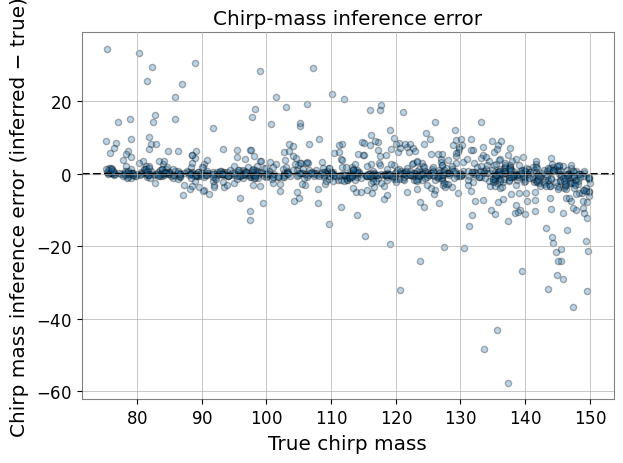

1000 samples in range 50 - 1000
Mean error (bias):      -0.015
Mean absolute error:    3.393
RMS error:              6.760
Std of error:           6.760
90th percentile |error|: 8.374
95th percentile |error|: 14.309
98th percentile |error|: 24.061
99th percentile |error|: 29.400


0

In [ ]:
scatter_chirpmass(name, 50, 1000)


In [ ]:
scatter_chirpmass("stage1", 75, 150)

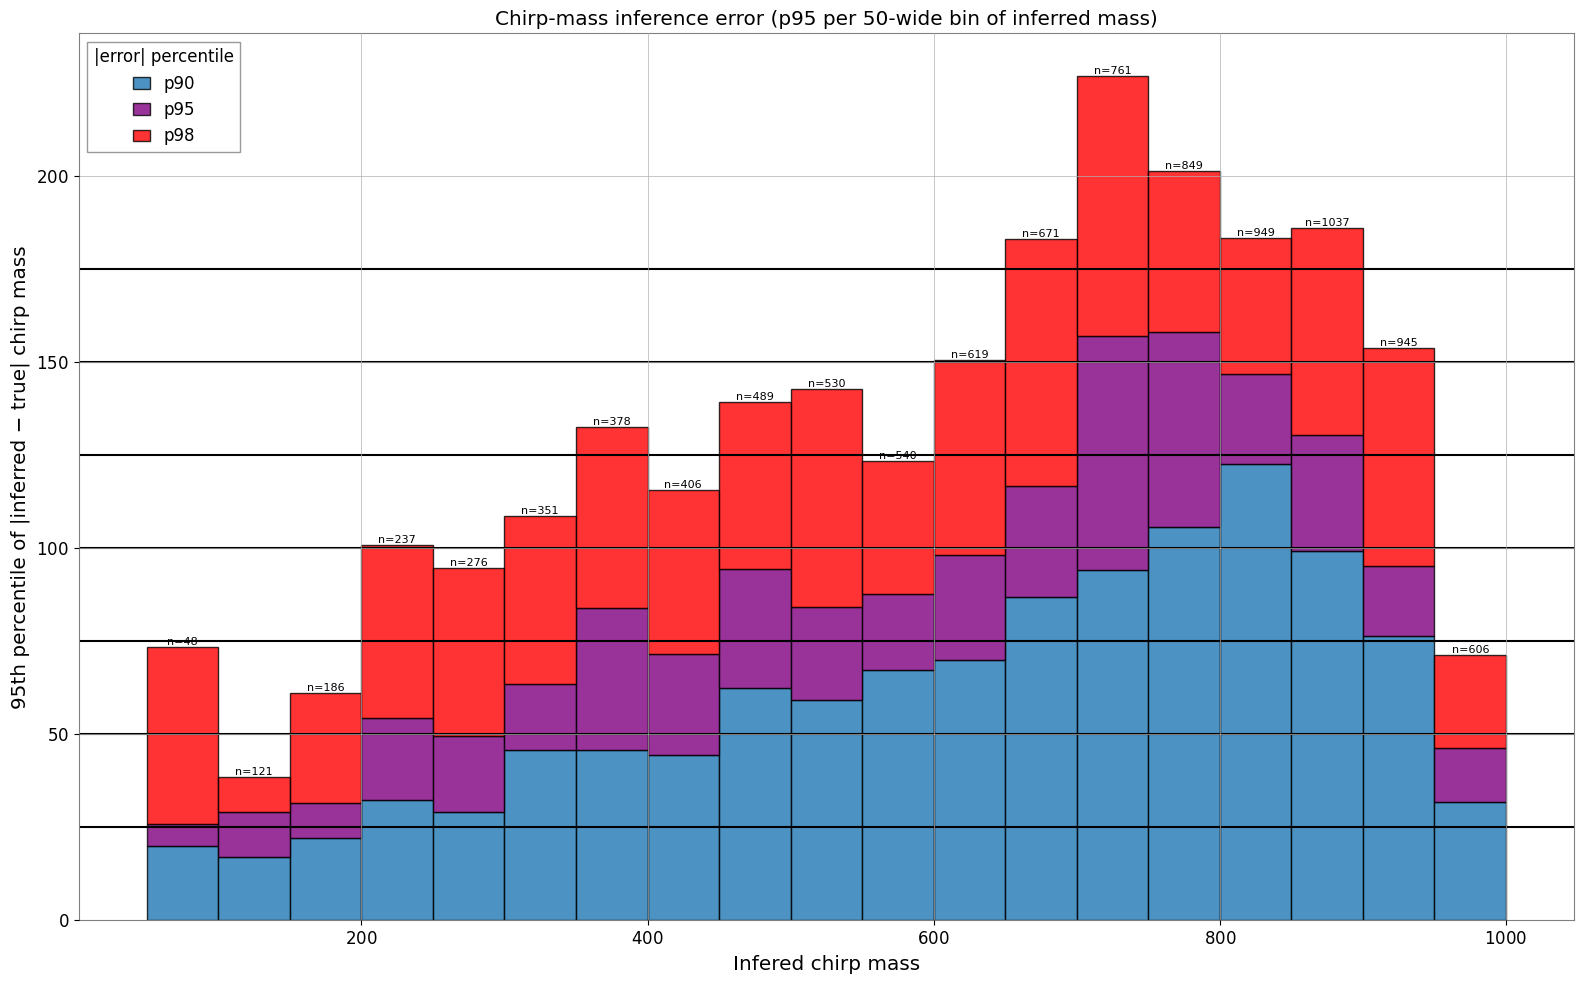

0

In [21]:
hist_chirpmass_909598(name, 50, 1000, bin_width=50)

 bin        mass low        mass high       mass range
   0           70.00            85.00            15.00
   1           70.00           100.00            30.00
   2           80.00           110.00            30.00
   3           90.00           120.00            30.00
   4           95.00           140.00            45.00
   5          110.00           155.00            45.00
   6          130.00           160.00            30.00


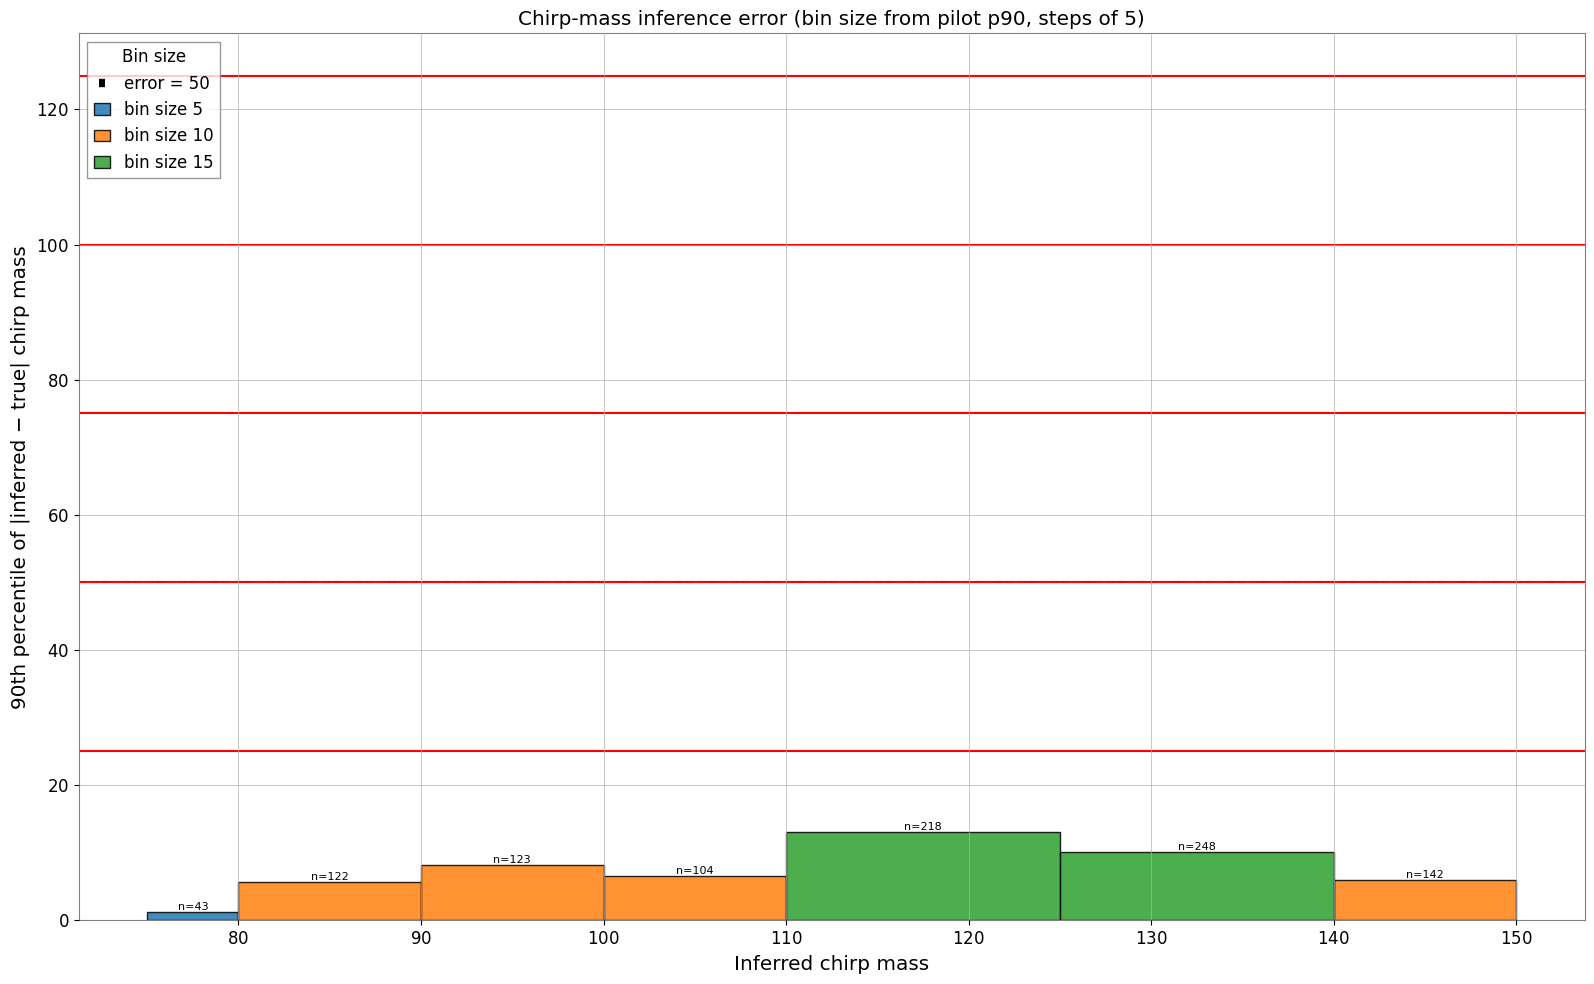

In [13]:
edges, left, right, widths, mr_low, mr_high = hist_chirpmass_dynamic(name, 75, 150, 90, n_it=15, step=5, min_events=5)
mass_ranges = list(zip(mr_low, mr_high))

# SNR


In [33]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt


def plot_chirpmass_SNR(name, cm_min, cm_max, top_percent=10):
    if not (0 < top_percent < 100):
        raise ValueError("top_percent must be between 0 and 100 (e.g. 10 for the worst 10%)")

    results_dir = f"/scratch/tpausch/test_data/{name}/results"
    inferred_cm, cm_err, snr_events = [], [], []

    for fname in sorted(os.listdir(results_dir)):
        with open(os.path.join(results_dir, fname), "rb") as f:
            payload = pickle.load(f)

        # filter on true chirp mass
        true_cm = payload["theta_true"]["chirp_mass"]
        if not (cm_min <= true_cm <= cm_max):
            continue

        cm_median = np.median(np.asarray(payload["result"].samples["chirp_mass"]))

        inferred_cm.append(cm_median)
        cm_err.append(cm_median - true_cm)
        snr_events.append(payload["network_snr"])  # appended AFTER the filter

    inferred_cm = np.array(inferred_cm)
    abs_err = np.abs(np.array(cm_err))
    snr_events = np.array(snr_events)

    # keep only the top `top_percent`% with the largest |error|
    threshold = np.percentile(abs_err, 100 - top_percent)
    sel = abs_err >= threshold

    snr_sel = snr_events[sel]
    print(f"Selected events: {sel.sum()} of {len(abs_err)}")
    print(f"Selected SNR: mean = {np.mean(snr_sel):.2f}, median = {np.median(snr_sel):.2f}")
    print(f"All events SNR: mean = {np.mean(snr_events):.2f}, median = {np.median(snr_events):.2f}")

    fig, ax = plt.subplots(figsize=(16, 10))
    sc = ax.scatter(inferred_cm[sel], abs_err[sel], c=snr_events[sel],
                    cmap="viridis", alpha=0.7, s=15, rasterized=True)

    ax.axhline(50, linestyle="--", color="black", label="error = 50")
    ax.axhline(threshold, linestyle=":", color="red",
               label=f"{100 - top_percent:g}th percentile = {threshold:.3g}")

    ax.set_xlabel("Inferred chirp mass")
    ax.set_ylabel("|inferred − true| chirp mass")
    ax.set_title(f"Top {top_percent:g}% largest chirp-mass errors "
                 f"({sel.sum()} of {len(abs_err)} events)")
    ax.grid(True, axis="y")
    ax.legend(loc="upper left")
    fig.colorbar(sc, ax=ax, label="Network SNR")
    fig.tight_layout()
    plt.show()

    return 0

Selected events: 1000 of 10000
Selected SNR: mean = 42.58, median = 21.31
All events SNR: mean = 322.11, median = 120.25


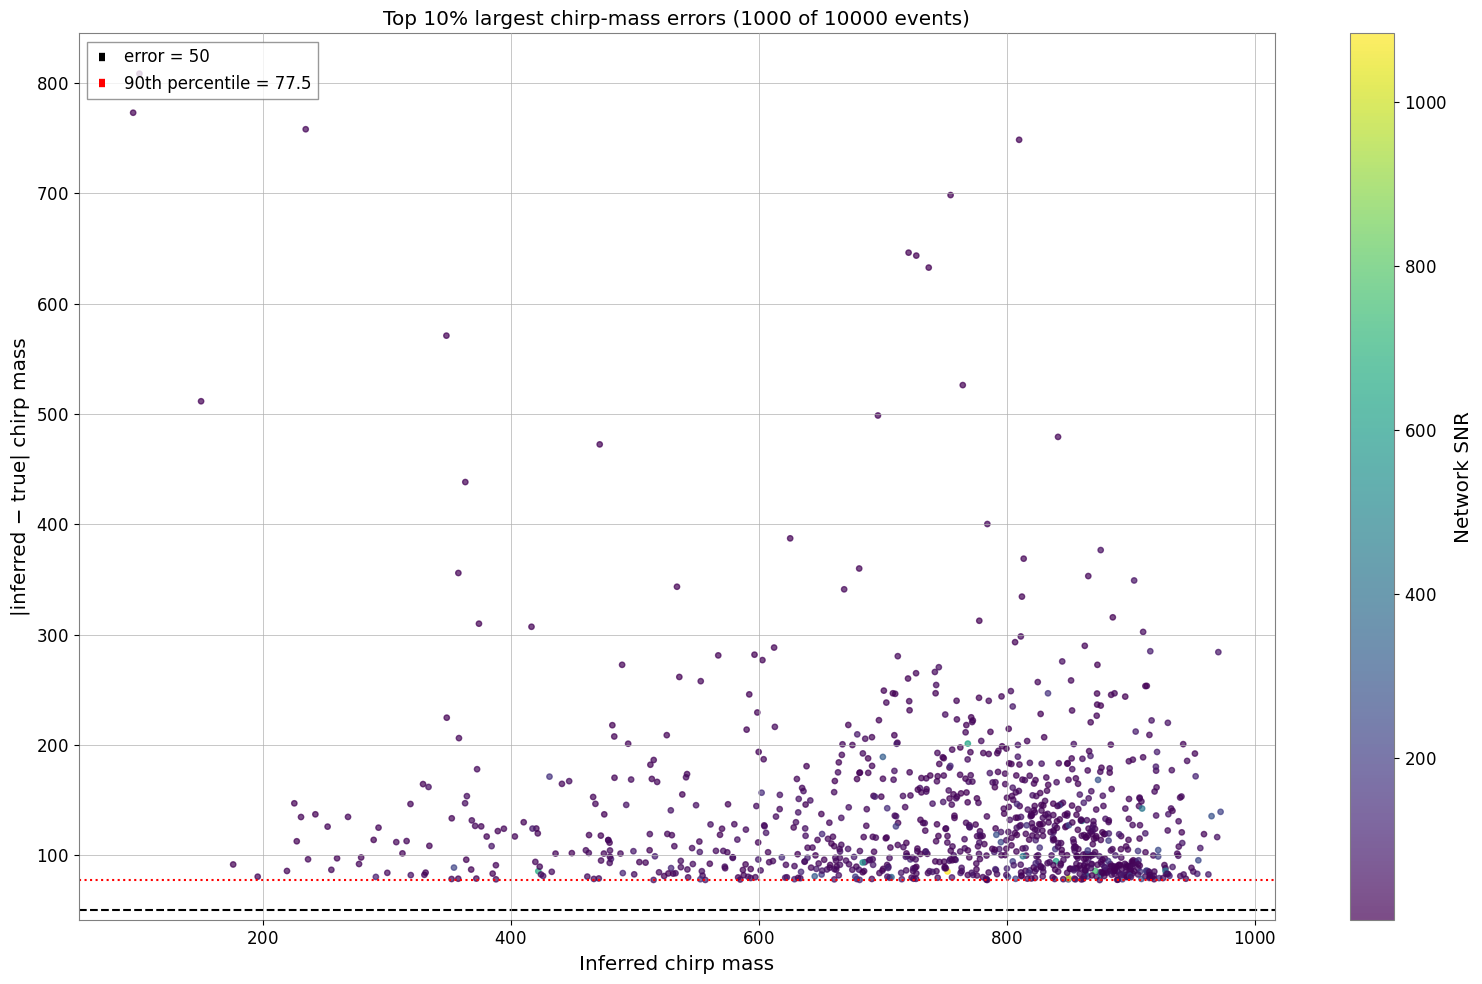

0

In [34]:
plot_chirpmass_SNR(name, 50, 1000)

In [ ]:
def scatter_top_per_bin(name, cm_min, cm_max, perr, top_percent=10, snr_cut_percent=10,
                        pilot_width=50, step=25, min_events=5, n_it=1):
    if not (0 < perr < 100):
        raise ValueError("perr must be between 0 and 100 (e.g. 90 for the 90th percentile)")
    if not (0 < top_percent < 100):
        raise ValueError("top_percent must be between 0 and 100")

    results_dir = f"/scratch/tpausch/test_data/{name}/results"
    inferred_cm, chirp_mass_error, snr_events = [], [], []

    for fname in sorted(os.listdir(results_dir)):
        with open(os.path.join(results_dir, fname), "rb") as f:
            payload = pickle.load(f)

        true_cm = payload["theta_true"]["chirp_mass"]
        if not (cm_min <= true_cm <= cm_max):
            continue

        cm_median = np.median(np.asarray(payload["result"].samples["chirp_mass"]))
        inferred_cm.append(cm_median)
        chirp_mass_error.append(cm_median - true_cm)
        snr_events.append(payload["network_snr"])   # after the filter

    inferred_cm = np.array(inferred_cm)
    cm_err = np.array(chirp_mass_error)
    abs_err = np.abs(cm_err)
    snr_events = np.array(snr_events)
    abs_err = np.abs(cm_err)

    # ------------------------------------------------------------
    # Dynamic binning (same as before)
    # ------------------------------------------------------------
    edges = np.append(np.arange(cm_min, cm_max, pilot_width), cm_max)
    for it in range(n_it):
        edges = edges_from_pilot(inferred_cm, cm_err, edges, cm_min, cm_max, perr,
                                 step=step, min_events=min_events, default_size=pilot_width)
        

    n_bins = len(edges) - 1
    widths = np.diff(edges)

    # ------------------------------------------------------------
    # Top `top_percent`% of |error| within each bin
    # ------------------------------------------------------------
    idx = np.digitize(inferred_cm, edges) - 1
    sel = np.zeros(len(abs_err), dtype=bool)
    thresholds = np.full(n_bins, np.nan)
    counts = np.zeros(n_bins, dtype=int)
    n_sel = np.zeros(n_bins, dtype=int)

    for i in range(n_bins):
        in_bin = idx == i
        counts[i] = in_bin.sum()
        if counts[i] == 0:
            continue
        thresholds[i] = np.percentile(abs_err[in_bin], 100 - top_percent)
        sel_bin = in_bin & (abs_err >= thresholds[i])
        sel |= sel_bin
        n_sel[i] = sel_bin.sum()

    # ------------------------------------------------------------
    # Among the selected events, drop the highest `snr_cut_percent`% of SNR
    # ------------------------------------------------------------
    sel_all = sel.copy()   # selection before the SNR cut
    if snr_cut_percent > 0 and sel_all.any():
        snr_max = np.percentile(snr_events[sel_all], 100 - snr_cut_percent)
        sel = sel_all & (snr_events <= snr_max)
        print(f"SNR cut at {snr_max:.2f}: removed {sel_all.sum() - sel.sum()} "
              f"of {sel_all.sum()} selected events")

    snr_sel = snr_events[sel]
    print(f"\nSelected events: {sel.sum()} of {len(abs_err)}")
    print(f"Selected SNR:   mean = {np.mean(snr_events[sel]):.2f}, median = {np.median(snr_events[sel]):.2f}")
    print(f"Pre-cut selected SNR: mean = {np.mean(snr_events[sel_all]):.2f}, "
          f"median = {np.median(snr_events[sel_all]):.2f}")
    print(f"All events SNR: mean = {np.mean(snr_events):.2f}, median = {np.median(snr_events):.2f}")

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(16, 10))
    sc = ax.scatter(inferred_cm[sel], abs_err[sel], c=snr_events[sel],
                    cmap="viridis", alpha=0.8, s=20, rasterized=True)

    # bin boundaries
    for e in edges:
        ax.axvline(e, color="grey", linewidth=0.5, alpha=0.6)

    # per-bin selection threshold
    filled = counts > 0
    ax.hlines(thresholds[filled], edges[:-1][filled], edges[1:][filled],
              colors="red", linestyles=":", linewidth=1.5,
              label=f"per-bin {100 - top_percent:g}th percentile")

    ax.axhline(50, linestyle="--", color="black", label="error = 50")

    ax.set_xlabel("Inferred chirp mass")
    ax.set_ylabel("|inferred − true| chirp mass")
    ax.set_title(f"Top {top_percent:g}% largest chirp-mass errors per bin "
                 f"({sel.sum()} of {len(abs_err)} events; bins from pilot p{perr}, steps of {step})")
    ax.grid(True, axis="y")
    ax.legend(loc="upper left")
    fig.colorbar(sc, ax=ax, label="Network SNR")
    fig.tight_layout()
    plt.show()

    return 0

SNR cut at 82.80: removed 101 of 1008 selected events

Selected events: 907 of 10000
Selected SNR:   mean = 25.00, median = 19.78
Pre-cut selected SNR: mean = 42.63, median = 22.33
All events SNR: mean = 322.11, median = 120.25


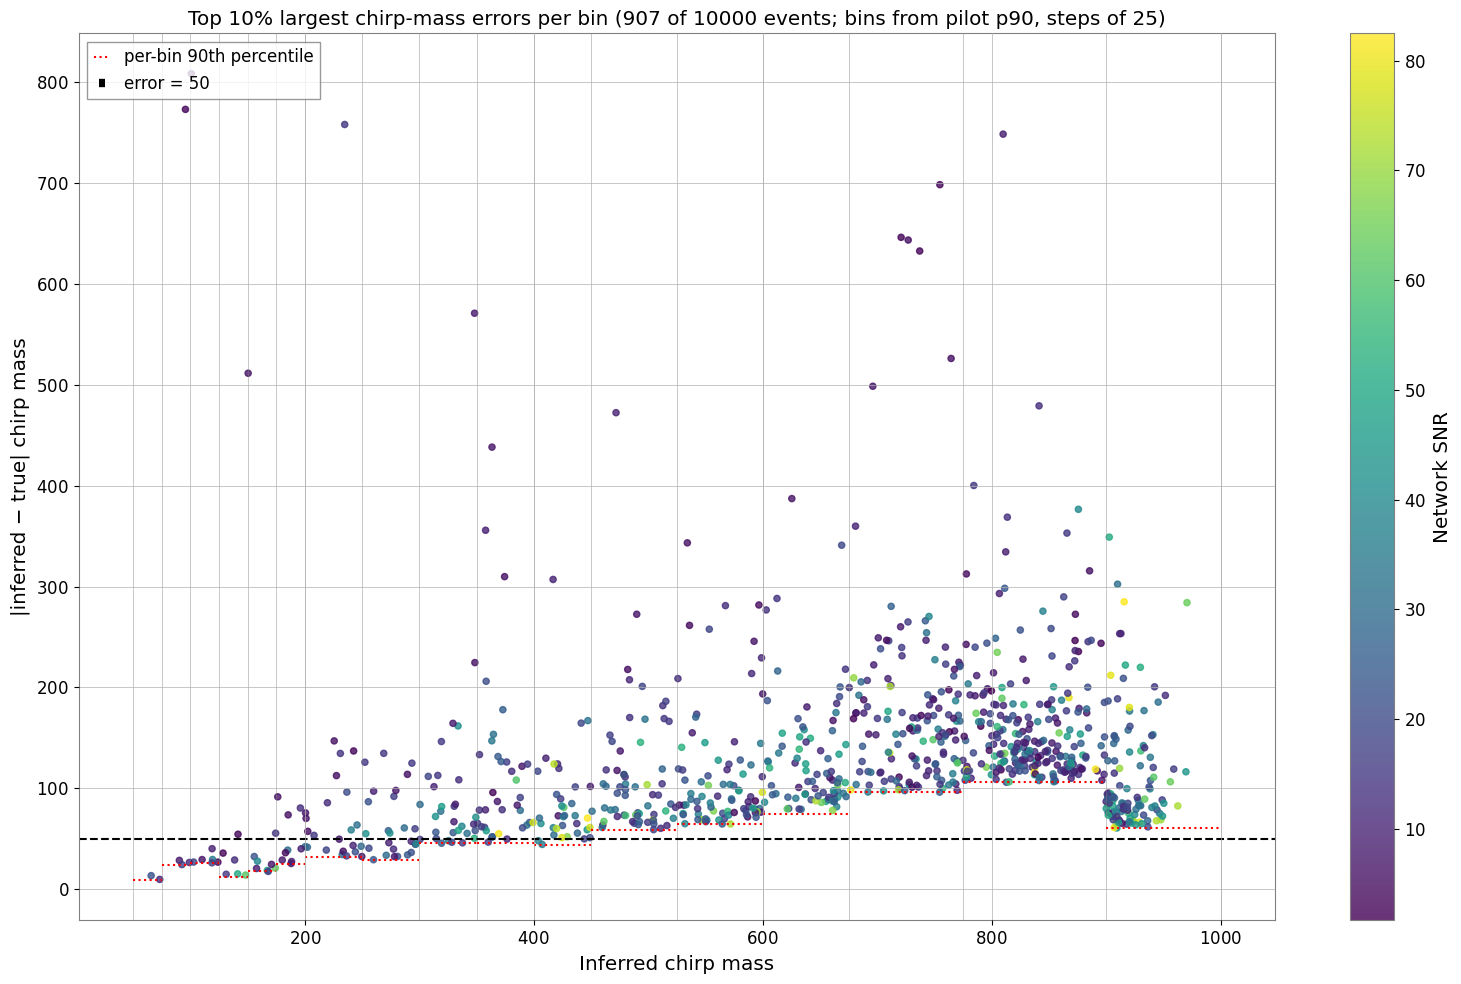

(array([  50,   75,  100,  125,  150,  175,  200,  250,  300,
         350,  400,  450,  525,  600,  675,  775,  900, 1000]),
 array([ True, False, False, ...,  True, False, False]),
 array([  9.16716773,  24.43000737,  26.13687536,  12.64438834,
         17.70301207,  25.30105986,  32.35962162,  29.15997457,
         45.63103671,  45.84910855,  44.35568084,  58.37939928,
         64.71229268,  74.23051077,  96.19112014, 105.94285074,
         60.72872876]))

In [55]:
scatter_top_per_bin(name, 50, 1000, perr=90)

# Injected Value inside posterior?


In [52]:

def posterior_check(name, min=50, max=1000):
    CM_MIN, CM_MAX = min, max
    true_cm = []
    chirp_mass_error = []
    median_cm = [] 
    in_posterior = []


    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

          # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        if not (CM_MIN <= true_chirp_mass <= CM_MAX):
            continue

        result = payload["result"]

        posterior_samples = result.samples


        cm_samples = np.array(posterior_samples["chirp_mass"])

    
        cm_p99 = np.percentile(cm_samples, 99)
        cm_p1 = np.percentile(cm_samples, 1)

        if cm_p1 <= theta_true["chirp_mass"] <= cm_p99:
            in_posterior.append(True)
        else:
            in_posterior.append(False)

   

   
       
        


   

    #calulate percentage of true chirp mass within 1-99 percentile of posterior samples
    in_posterior = np.array(in_posterior)
    percentage_in_posterior = np.sum(in_posterior) / len(in_posterior) * 100
    print(f"Percentage of true chirp mass within 1-99 percentile of posterior samples: {percentage_in_posterior:.2f}%")

    return 0

In [53]:
posterior_check(name)

Percentage of true chirp mass within 1-99 percentile of posterior samples: 98.42%


0

## PP-plot

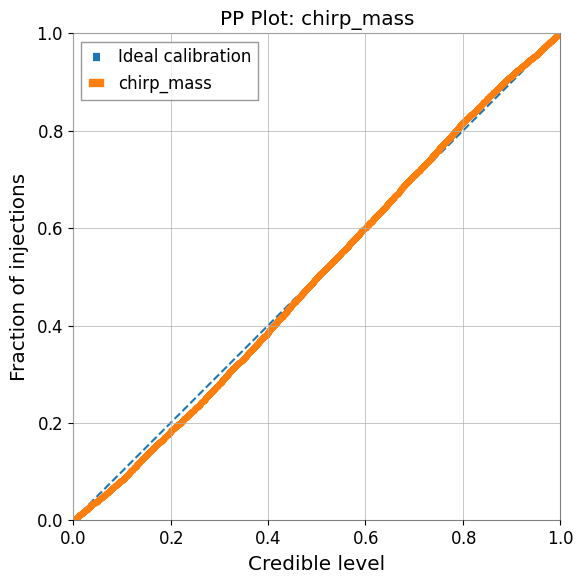

In [25]:
pp_values_chirp_mass = []
pp_values_mass_ratio = []

result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

for fname in result_files:

    with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:

        payload = pickle.load(f)

        theta_true = payload["theta_true"]
        result = payload["result"]

        posterior_samples = result.samples


        # ============================================================
        # Chirp mass PP value
        # ============================================================

        cm_samples = posterior_samples["chirp_mass"]

        pp_cm = np.mean(
            cm_samples < theta_true["chirp_mass"]
        )

        pp_values_chirp_mass.append(pp_cm)


        # ============================================================
        # Mass ratio PP value
        # ============================================================

        #q_samples = posterior_samples["mass_ratio"]
#
        #pp_q = np.mean(
        #    q_samples < theta_true["mass_ratio"]
        #)
#
        #pp_values_mass_ratio.append(pp_q)




def plot_pp(pp_values, label):

    pp_values = np.array(pp_values)

    sorted_pp = np.sort(pp_values)

    n = len(sorted_pp)

    empirical_cdf = np.arange(1, n + 1) / n

    x = np.linspace(0, 1, 200)

    sigma = np.sqrt(x * (1 - x) / n)

    plt.figure(figsize=(6, 6))

    # Ideal calibration
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Ideal calibration",
    )


    # Empirical PP curve
    plt.plot(
        sorted_pp,
        empirical_cdf,
        marker="o",
        markersize=3,
        label=label,
    )

    plt.xlabel("Credible level")
    plt.ylabel("Fraction of injections")

    plt.title(f"PP Plot: {label}")

    plt.xlim(0, 1)
    plt.ylim(0, 1)

    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()


plot_pp(
    pp_values_chirp_mass,
    "chirp_mass",
)

#plot_pp(
#    pp_values_mass_ratio,
#    "mass_ratio",
#)